# Machine Learning Assignment 2
## Dry Bean Classification and Streamlit Evaluation

**Student:** P Tejeswara Varma  
**BITS ID:** 2026AJ05571

This notebook trains and evaluates Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes and Support Vector Machine models on the same UCI Dry Bean dataset. All required metrics are calculated on one untouched stratified test split, and every trained model is saved for evaluation through the accompanying Streamlit application.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.metrics import confusion_matrix

from train_models import (
    FEATURE_COLUMNS,
    MODEL_FILES,
    TARGET_COLUMN,
    load_dry_bean_dataset,
    main,
)

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "train_models.py").exists():
    raise FileNotFoundError("Run this notebook from the ML_Assignment_2 project folder.")

pd.set_option("display.max_columns", None)
print(f"Project directory: {PROJECT_DIR}")

Project directory: D:\Assign\ML_Assignment_2


## 1. Dataset selection and validation

The project uses the public **UCI Dry Bean Dataset**. The raw data contains 13,611 bean records, 16 numerical input features and seven target classes. This satisfies the assignment thresholds of at least 500 instances and 12 features. Exact duplicate records are removed before splitting to prevent the same observation from appearing in both training and test data.

In [2]:
raw_data = load_dry_bean_dataset()
duplicate_count = int(raw_data.duplicated().sum())
data = raw_data.drop_duplicates().reset_index(drop=True)

print(f"Raw shape: {raw_data.shape}")
print(f"Exact duplicates removed: {duplicate_count}")
print(f"Modelling shape: {data.shape}")
print(f"Missing values: {int(data.isna().sum().sum())}")
print(f"Input features: {len(FEATURE_COLUMNS)}")
print("\nClass distribution:")
display(data[TARGET_COLUMN].value_counts().sort_index().rename("Count").to_frame())
print("\nFirst five records:")
display(data.head())

Raw shape: (13611, 17)
Exact duplicates removed: 68
Modelling shape: (13543, 17)
Missing values: 0
Input features: 16

Class distribution:


,Count
Class,
BARBUNYA,1322
BOMBAY,522
CALI,1630
DERMASON,3546
HOROZ,1860
SEKER,2027
SIRA,2636



First five records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


## 2. Model training and required evaluation metrics

A stratified 80:20 split with random state 42 is shared by all five models. Scaling is fitted only on training data through model pipelines. Accuracy, weighted one-vs-rest AUC, weighted precision, weighted recall, weighted F1 and Matthews Correlation Coefficient are calculated on the same untouched test records. The cell below also saves every trained model and generates `test_data.csv` for the Streamlit application.

In [3]:
comparison = main(PROJECT_DIR)

metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]
print("\nFinal comparison table (sorted by weighted F1):")
display(
    comparison[["ML Model Name", *metric_columns]]
    .reset_index(drop=True)
    .style.format({column: "{:.4f}" for column in metric_columns})
)

Raw dataset shape: (13611, 17)
Modeling dataset shape after duplicate removal: (13543, 17)
Missing values: 0
Duplicate rows removed: 68
Class distribution:
Class
BARBUNYA    1322
BOMBAY       522
CALI        1630
DERMASON    3546
HOROZ       1860
SEKER       2027
SIRA        2636
Name: count, dtype: int64

Training Logistic Regression...


Accuracy=0.9147, AUC=0.9932, Precision=0.9162, Recall=0.9147, F1=0.9150, MCC=0.8973

Training Decision Tree...


Accuracy=0.8922, AUC=0.9567, Precision=0.8931, Recall=0.8922, F1=0.8925, MCC=0.8699

Training K-Nearest Neighbors...


C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\tejas\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036

Accuracy=0.9136, AUC=0.9835, Precision=0.9144, Recall=0.9136, F1=0.9138, MCC=0.8956

Training Gaussian Naive Bayes...
Accuracy=0.8970, AUC=0.9899, Precision=0.8997, Recall=0.8970, F1=0.8972, MCC=0.8762

Training Support Vector Machine...


Accuracy=0.9262, AUC=0.9933, Precision=0.9269, Recall=0.9262, F1=0.9263, MCC=0.9109

Model comparison:
         ML Model Name  Accuracy      AUC  Precision   Recall       F1      MCC
Support Vector Machine  0.926172 0.993310   0.926886 0.926172 0.926310 0.910912
   Logistic Regression  0.914729 0.993185   0.916246 0.914729 0.914980 0.897309
   K-Nearest Neighbors  0.913621 0.983471   0.914400 0.913621 0.913803 0.895555
  Gaussian Naive Bayes  0.897010 0.989880   0.899653 0.897010 0.897199 0.876171
         Decision Tree  0.892211 0.956660   0.893148 0.892211 0.892501 0.869859

Overall winner by weighted F1: Support Vector Machine
Saved test data to: D:\Assign\ML_Assignment_2\test_data.csv
Saved trained models to: D:\Assign\ML_Assignment_2\model

Final comparison table (sorted by weighted F1):


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Support Vector Machine,0.9262,0.9933,0.9269,0.9262,0.9263,0.9109
1,Logistic Regression,0.9147,0.9932,0.9162,0.9147,0.9150,0.8973
2,K-Nearest Neighbors,0.9136,0.9835,0.9144,0.9136,0.9138,0.8956
3,Gaussian Naive Bayes,0.8970,0.9899,0.8997,0.8970,0.8972,0.8762
4,Decision Tree,0.8922,0.9567,0.8931,0.8922,0.8925,0.8699


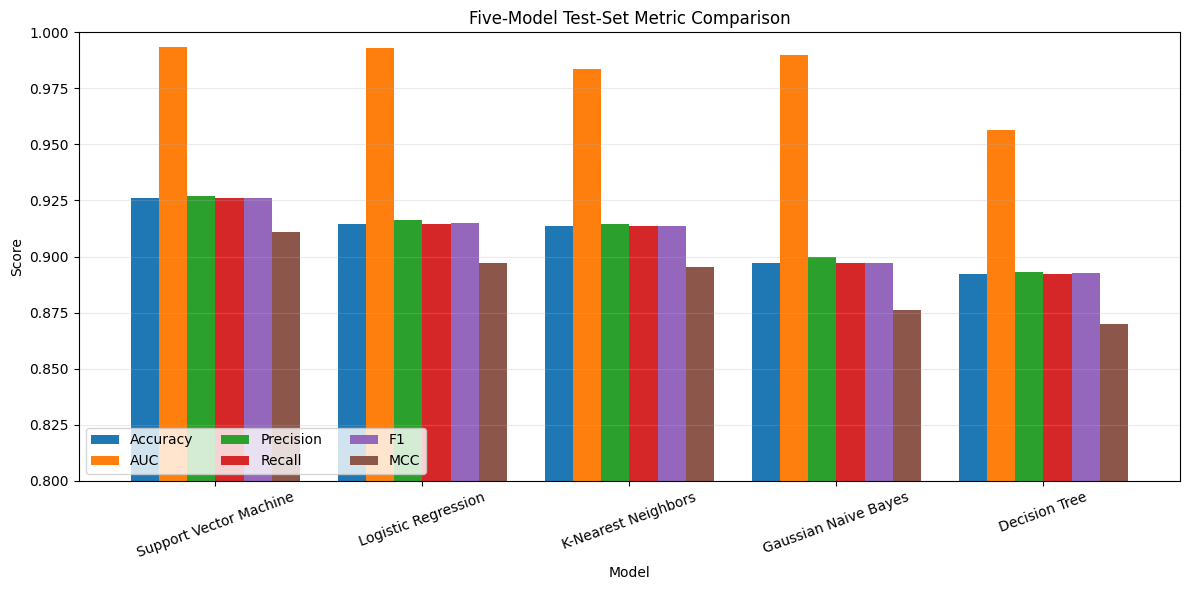

In [4]:
plot_data = comparison.set_index("ML Model Name")[metric_columns]
axis = plot_data.plot(kind="bar", figsize=(12, 6), width=0.82)
axis.set_title("Five-Model Test-Set Metric Comparison")
axis.set_xlabel("Model")
axis.set_ylabel("Score")
axis.set_ylim(0.80, 1.00)
axis.tick_params(axis="x", rotation=20)
axis.legend(ncol=3, loc="lower left")
axis.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

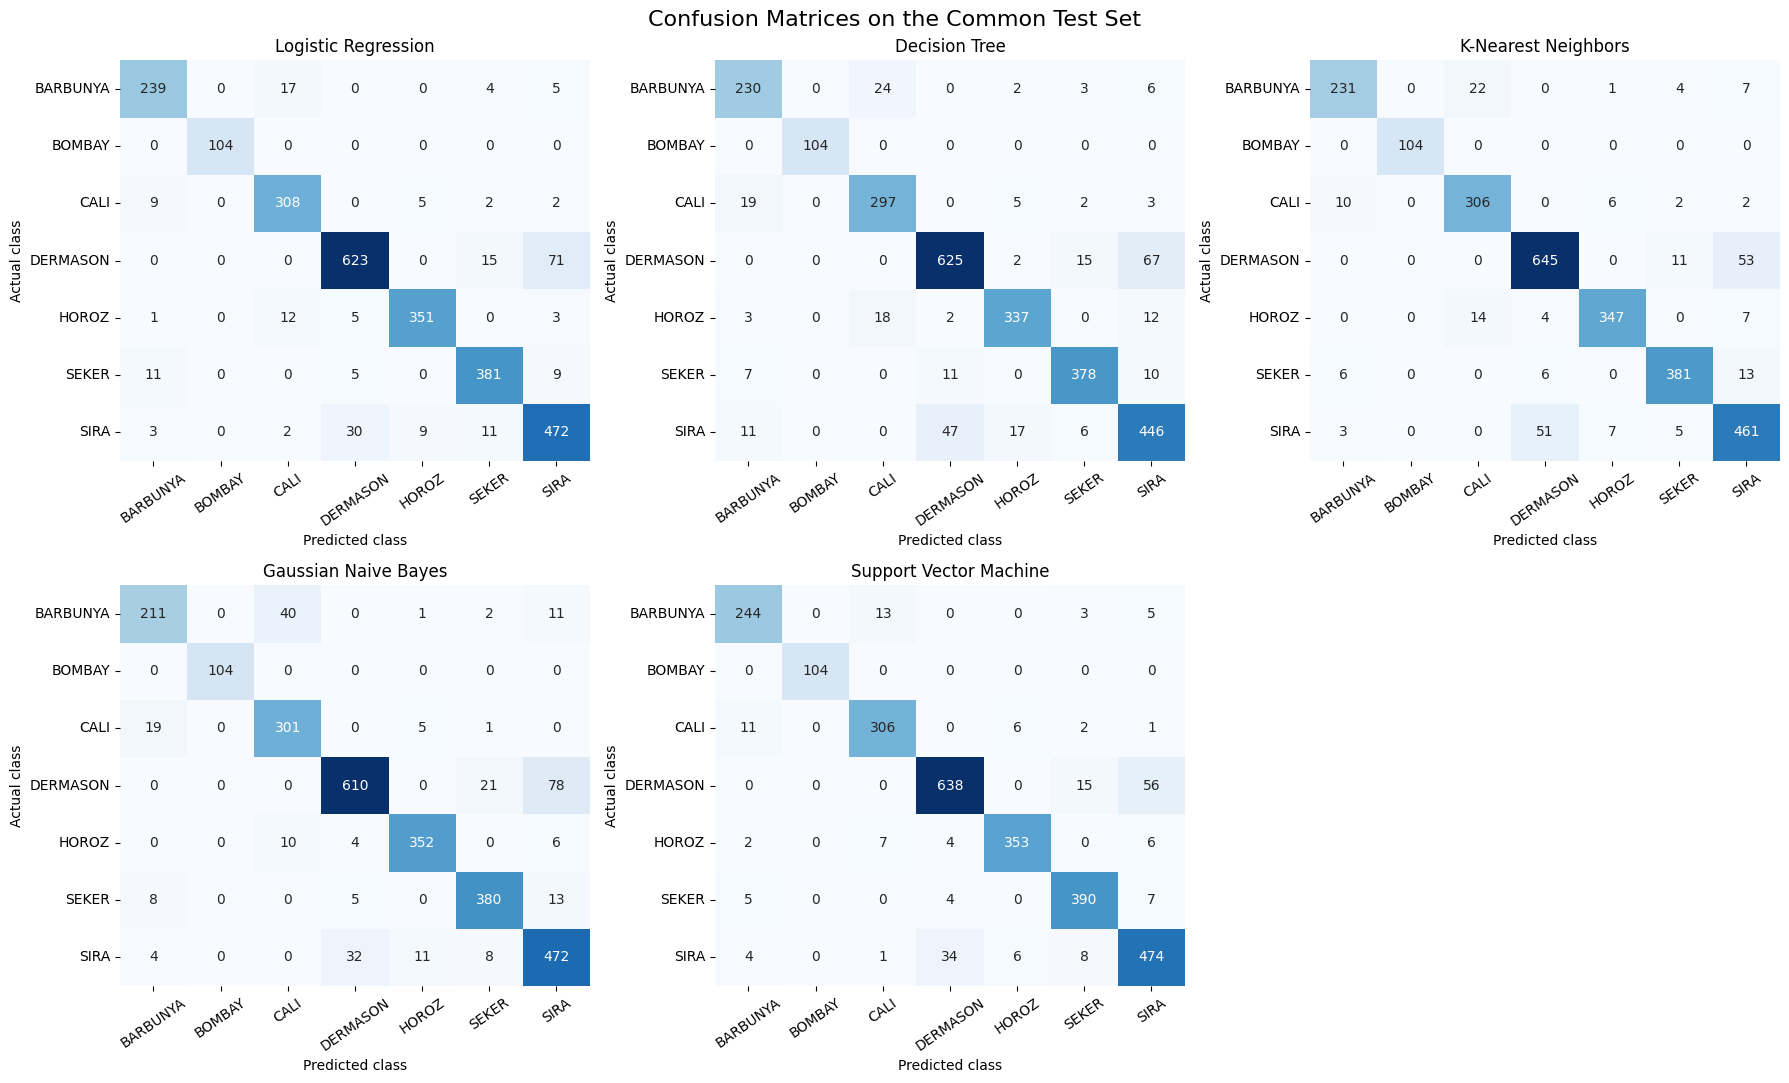

In [5]:
test_data = pd.read_csv(PROJECT_DIR / "test_data.csv")
X_test = test_data[FEATURE_COLUMNS]
y_test = test_data[TARGET_COLUMN]

figure, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.ravel()
for axis, (model_name, filename) in zip(axes, MODEL_FILES.items()):
    model = joblib.load(PROJECT_DIR / "model" / filename)
    predictions = model.predict(X_test)
    matrix = confusion_matrix(y_test, predictions, labels=model.classes_)
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=axis,
    )
    axis.set_title(model_name)
    axis.set_xlabel("Predicted class")
    axis.set_ylabel("Actual class")
    axis.tick_params(axis="x", rotation=35)
    axis.tick_params(axis="y", rotation=0)

axes[-1].axis("off")
figure.suptitle("Confusion Matrices on the Common Test Set", fontsize=16)
plt.tight_layout()
plt.show()

## 3. Performance observations

- **Logistic Regression:** Strong linear baseline with weighted F1 of 0.9150. Scaling and balanced class weights produced stable multiclass performance.
- **Decision Tree:** Its interpretable nonlinear rules achieved weighted F1 of 0.8925, but it was more sensitive to model complexity and produced the lowest AUC.
- **K-Nearest Neighbors:** Scaling allowed local neighbourhoods to perform competitively, reaching weighted F1 of 0.9138. Prediction requires retaining and searching the training observations.
- **Gaussian Naive Bayes:** Fast probabilistic baseline with high AUC, but its Gaussian conditional-independence assumptions reduced accuracy and weighted F1 to 0.8972.
- **Support Vector Machine:** Best overall model, with accuracy 0.9262, weighted F1 0.9263 and MCC 0.9109. The RBF kernel captured nonlinear separation between overlapping bean classes.

**Overall winner:** Support Vector Machine, selected by the highest weighted F1, with the highest accuracy and MCC providing supporting evidence.

## 4. Streamlit application readiness

The application loads the five saved model artifacts and never retrains on uploaded test data. It accepts a labelled CSV containing all 16 input features and the `Class` target, displays the six required metrics for every model, and provides a selected-model confusion matrix and classification report.

In [6]:
required_files = [
    PROJECT_DIR / "app.py",
    PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / "README.md",
    PROJECT_DIR / "test_data.csv",
    PROJECT_DIR / "artifacts" / "metadata.json",
    PROJECT_DIR / "artifacts" / "model_comparison.csv",
]
required_files.extend(PROJECT_DIR / "model" / filename for filename in MODEL_FILES.values())

readiness = pd.DataFrame(
    {"Required artifact": [path.relative_to(PROJECT_DIR).as_posix() for path in required_files],
     "Available": [path.is_file() for path in required_files]}
)
display(readiness)
assert readiness["Available"].all(), "One or more required deployment artifacts are missing."
print("All local repository and deployment artifacts are ready.")

,Required artifact,Available
0,app.py,True
1,requirements.txt,True
2,README.md,True
3,test_data.csv,True
4,artifacts/metadata.json,True
5,artifacts/model_comparison.csv,True
6,model/logistic_regression.joblib,True
7,model/decision_tree.joblib,True
8,model/knn.joblib,True
9,model/gaussian_naive_bayes.joblib,True


All local repository and deployment artifacts are ready.


## 5. Submission completion steps

The implementation, saved models, common test set and Streamlit application are complete locally. Before submitting the single required PDF:

1. Push this project folder to a public GitHub repository and replace the GitHub placeholder in `README.md`.
2. Deploy `app.py` on Streamlit Community Cloud and replace the application-link placeholder.
3. Execute the project in the BITS Virtual Lab, capture the required screenshot, and add it to the final report.
4. Include the GitHub URL, deployed Streamlit URL, BITS Lab screenshot and README content in the final PDF.